# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
- **Name: Krishna Lund**
- **Student ID: 023-24-0271**
- **Section: H**
- **GitHub: https://github.com/Krishnalund/machine-learning-practical-work**
- **Kaggle: https://www.kaggle.com/krishnalund18**
- **Dataset: Stroke Prediction Dataset (Kaggle)**
- **Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset**


# Part 0 — Setup and the Data

**1. Install imbalanced-learn (pip install imbalanced-learn) and import everything you need.**

In [1]:
!pip install imbalanced-learn -q

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


**2. Load the CSV. Report the shape, the columns with missing values, the value counts of gender and the
number of patients with stroke = 1 and stroke = 0 (count and percentage).**

In [2]:
df = pd.read_csv('healthcare-dataset-stroke-data_1.csv')
print("Shape:", df.shape)
mv = df.isnull().sum(); print("Missing values:\n", mv[mv > 0])
print(df['gender'].value_counts())
vc = df['stroke'].value_counts()
print(pd.DataFrame({'count': vc, 'percent': (vc / len(df) * 100).round(2)}))

Shape: (5110, 12)
Missing values:
 bmi    201
dtype: int64
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
        count  percent
stroke                
0        4861    95.13
1         249     4.87


**Explanation**
*The dataset contains 5,110 patients and 12 columns. During initial data inspection, we found 201 missing values in the BMI column. The gender distribution includes 2,994 females, 2,115 males, and 1 patient categorized as Other. The dataset is highly imbalanced, as only 249 patients (4.87%) had a stroke, while 4,861 patients (95.13%) did not. This imbalance is important because the model may become biased toward predicting the non-stroke class.*

**3. Clean the data: remove the identifier column; remove any gender category that has too few rows to learn or
test; apply categorical encoding to the text columns (pd.get_dummies, as in the labs).**


In [3]:
df = df.drop(columns=['id'])
df = df[df['gender'] != 'Other']          
df = pd.get_dummies(df, drop_first=True).astype(float)
X = df.drop(columns='stroke'); y = df['stroke']
print(X.shape, y.shape)

(5109, 15) (5109,)


**4. Split 80/20 with stratify=y and random_state=SEED. Fill the missing numeric values with a median learned
from the TRAIN set only. Create a scaled copy (StandardScaler fitted on train) to use for Logistic Regression.**

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

med = X_train.median()
X_train = X_train.fillna(med)
X_test = X_test.fillna(med)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Missing left in train/test:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Train shape: (4087, 15) | Test shape: (1022, 15)
Missing left in train/test: 0 0


**5. Report how many stroke cases are in the training set and in the test set.**


In [5]:
print("Strokes in train:", int(y_train.sum()), "of", len(y_train),
      f"({y_train.mean()*100:.2f}%)")
print("Strokes in test :", int(y_test.sum()), "of", len(y_test),
      f"({y_test.mean()*100:.2f}%)")

Strokes in train: 199 of 4087 (4.87%)
Strokes in test : 50 of 1022 (4.89%)


**Explanation:**
*The dataset was split into 80% training data and 20% testing data using stratification. The training set contains 4,087 patients, including 199 stroke cases (4.87%), while the test set contains 1,022 patients, including 50 stroke cases (4.89%). This shows that stratification maintained nearly the same stroke percentage in both sets. No missing values remain in either set after preprocessing.*

# Part 1 — The Accuracy Trap 

**1. Build a baseline that always predicts the majority class (DummyClassifier, strategy='most_frequent'). Report
accuracy.**


In [6]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print("Baseline accuracy:", round(accuracy_score(y_test, dummy.predict(X_test)), 4))

Baseline accuracy: 0.9511


**3. Write a small helper function that takes a model and train/test data and returns these six metrics - you will reuse it all lab. (a)Compare the accuracy of the baseline and of Logistic Regression. What do you conclude? (b)Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?**

In [7]:
def evaluate(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    return {'Accuracy': accuracy_score(yte, pred),
            'Precision': precision_score(yte, pred, zero_division=0),
            'Recall': recall_score(yte, pred),
            'F1': f1_score(yte, pred, zero_division=0),
            'ROC AUC': roc_auc_score(yte, proba),
            'PR AUC': average_precision_score(yte, proba)}

**2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC
AUC and PR AUC (average precision) on the test set, and plot or print its confusion matrix.**

Accuracy     0.9521
Precision    1.0000
Recall       0.0200
F1           0.0392
ROC AUC      0.8394
PR AUC       0.2692
dtype: float64


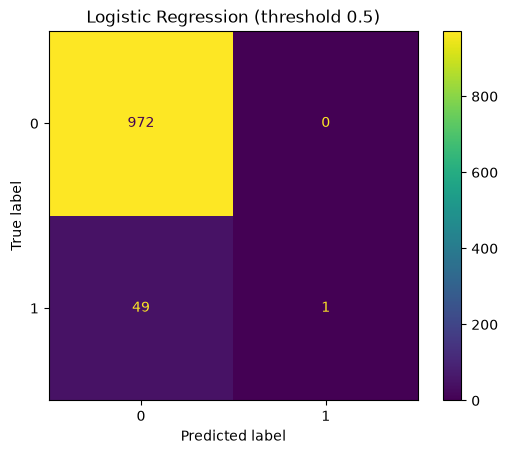

[[972   0]
 [ 49   1]]


In [8]:
lr = LogisticRegression(max_iter=1000)
res_lr = evaluate(lr, X_train_s, y_train, X_test_s, y_test)
print(pd.Series(res_lr).round(4))

cm = confusion_matrix(y_test, lr.predict(X_test_s))
ConfusionMatrixDisplay(cm).plot()
plt.title("Logistic Regression (threshold 0.5)")
plt.show()
print(cm)

**Explanation for Ques3(a):**
*The baseline model achieved 95.11% accuracy by predicting every patient as having no stroke. Logistic Regression achieved 95.21% accuracy, which is only slightly higher. However, Logistic Regression detected only 1 out of 50 stroke patients. This shows that accuracy is misleading for highly imbalanced datasets, because a model can achieve high accuracy while failing to identify most stroke patients.*

**Explanation for Ques3(b):**
*A false negative occurs when a patient who actually had a stroke is incorrectly predicted as having no stroke. This is dangerous in hospitals because the patient may not receive proper medical attention. Our model produced 49 false negatives out of 50 stroke patients, resulting in a recall of only 2%. Therefore, we should focus more on recall, F1-score, PR AUC, ROC AUC, and the confusion matrix rather than accuracy alone. Precision is also important, but in this case, its value of 1.0 is based on identifying only one stroke patient.*

# Part 2 — Underfitting, Overfitting, Bias and Variance 

# Task 2.1 — Validation curve


**1. For max_depth = 1, 2, ..., 15 and None, record the train ROC AUC and the 5-fold stratified cross-validation
ROC AUC (train data only).**

In [9]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]
tr_auc, cv_auc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    t.fit(X_train, y_train)
    tr_auc.append(roc_auc_score(y_train, t.predict_proba(X_train)[:, 1]))
    cv_auc.append(cross_val_score(t, X_train, y_train, cv=skf, scoring='roc_auc').mean())

**2. Plot both curves on one chart (labelled axes, title, legend). Report the best depth by CV AUC.**

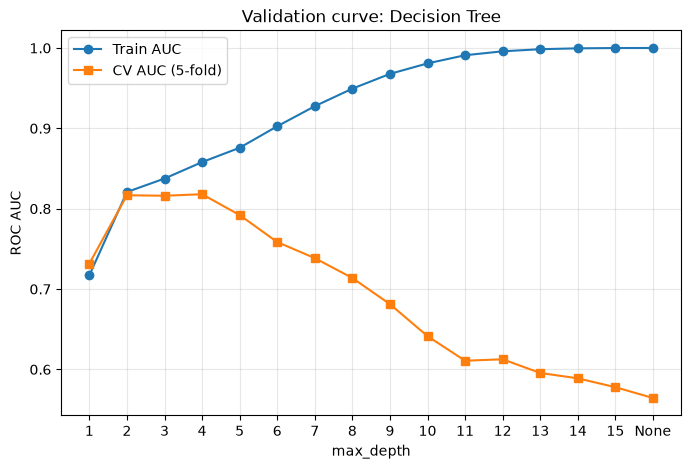

Best depth by CV AUC: 4 | CV AUC = 0.818


,depth,train_AUC,cv_AUC
0,1,0.7171,0.7317
1,2,0.8208,0.8168
2,3,0.8375,0.8161
3,4,0.8580,0.8180
4,5,0.8758,0.7921
5,6,0.9026,0.7585
6,7,0.9276,0.7385
7,8,0.9494,0.7138
8,9,0.9678,0.6812
9,10,0.9808,0.6414


In [10]:
labels = [str(d) for d in depths]
plt.figure(figsize=(8, 5))
plt.plot(labels, tr_auc, 'o-', label='Train AUC')
plt.plot(labels, cv_auc, 's-', label='CV AUC (5-fold)')
plt.xlabel('max_depth'); plt.ylabel('ROC AUC'); plt.title('Validation curve: Decision Tree')
plt.legend(); plt.grid(alpha=.3); plt.show()

best = depths[int(np.argmax(cv_auc))]
print("Best depth by CV AUC:", best, "| CV AUC =", round(max(cv_auc), 4))
pd.DataFrame({'depth': labels, 'train_AUC': np.round(tr_auc, 4), 'cv_AUC': np.round(cv_auc, 4)})

**Explanation:**
*The training ROC AUC increases as the tree depth increases, reaching 1.000 at unlimited depth. However, the cross-validation ROC AUC reaches its highest value of 0.818 at depth 4 and decreases afterward. This indicates that deeper trees start overfitting the training data and perform poorly on unseen data. Therefore, the best depth is 4, based on the highest cross-validation ROC AUC.*

# Task 2.2 — Learning curves

**1. Use sklearn.model_selection.learning_curve (scoring='roc_auc', train_sizes from 20% to 100%) for a tree with
max_depth=1 and a tree with max_depth=None. Plot train and CV AUC against the number of training rows,
side by side.**

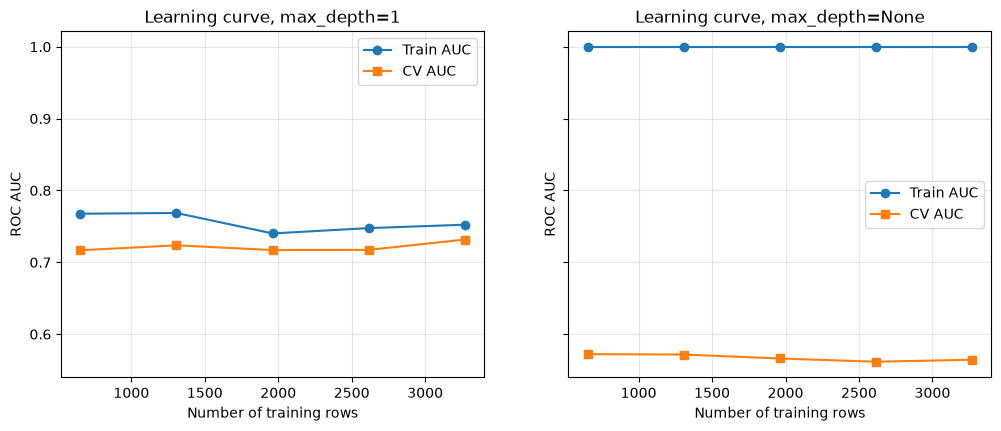

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, d in zip(axes, [1, None]):
    sizes, trs, vas = learning_curve(
        DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
        train_sizes=np.linspace(0.2, 1.0, 5), cv=skf, scoring='roc_auc')
    ax.plot(sizes, trs.mean(axis=1), 'o-', label='Train AUC')
    ax.plot(sizes, vas.mean(axis=1), 's-', label='CV AUC')
    ax.set_title(f'Learning curve, max_depth={d}')
    ax.set_xlabel('Number of training rows'); ax.set_ylabel('ROC AUC')
    ax.legend(); ax.grid(alpha=.3)
plt.show()

# Task 2.3 — Measure variance directly


**1. For each of max_depth = 1, 3 and None: draw 40 bootstrap samples of the TRAIN rows (sample with
replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test
patient.**

In [12]:
rng = np.random.default_rng(SEED)
all_probs, all_aucs = {}, {}
for d in [1, 3, None]:
    probs = np.zeros((40, len(X_test)))
    aucs = []
    for b in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        t.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = t.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_test, probs[b]))
    all_probs[d], all_aucs[d] = probs, aucs
print("Done. Each probs array has shape", all_probs[1].shape) 

Done. Each probs array has shape (40, 1022)


**2. For every test patient, compute the variance of its 40 predicted probabilities; then average over patients.
Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the averaged prediction (mean of the
40 probability vectors).**

In [13]:
rows = []
for d in [1, 3, None]:
    probs = all_probs[d]
    rows.append({'max_depth': str(d),
                 'Mean variance of predictions': probs.var(axis=0).mean(),
                 'Mean AUC of 40 single trees': np.mean(all_aucs[d]),
                 'AUC of averaged prediction': roc_auc_score(y_test, probs.mean(axis=0))})

**3. Show the three depths in one table.**

In [14]:
pd.DataFrame(rows).round(5)

,max_depth,Mean variance of predictions,Mean AUC of 40 single trees,AUC of averaged prediction
0,1,0.00068,0.76234,0.81317
1,3,0.00167,0.79644,0.83429
2,None,0.04197,0.55525,0.75659


**(a) Validation curve:**
*Depth 1 underfits because the model is too simple (Train AUC = 0.717, CV AUC = 0.732). Depths 2–4 give the best fit. Depth 8 and above overfit, especially depth None (Train AUC = 1.000, CV AUC = 0.564). I choose depth 4 because it has the highest CV AUC of 0.818.*

**(b) Learning curves:**
*High bias occurs when train and CV scores are both low and close together. High variance occurs when train score is high but CV score is much lower. More data may help high variance slightly, but limiting model complexity is more effective. More data does not fix high bias.*

**(c) Variance table:**
*Prediction variance increases with depth. Averaging predictions improves AUC, especially for deep trees. Random Forest uses multiple trees and averages their predictions to reduce overfitting and improve performance.*

**(d) Bias-variance trade-off:**
*Bias is caused by a model being too simple, while variance occurs when a model is too sensitive to training data. Depth 1 has high bias and low variance. Depth 3 provides a good balance. Depth None has low bias and high variance and overfits.*

# Part 3 — ROC, AUC, Precision-Recall and Thresholds

# Task 3.1 — Compare models with curves

**1. Train Logistic Regression (scaled), Decision Tree (max_depth=3) and Random Forest (200 trees,
min_samples_leaf=5, random_state=SEED) on the original training data.**

In [15]:
models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000), True),
    'Decision Tree (d=3)': (DecisionTreeClassifier(max_depth=3, random_state=SEED), False),
    'Random Forest': (RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                             random_state=SEED, n_jobs=-1), False)}
test_probs = {}
for name, (m, scaled) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if scaled else (X_train, X_test)
    m.fit(Xtr, y_train)
    test_probs[name] = m.predict_proba(Xte)[:, 1]

**2. Draw ROC curves for the three models on one chart with the AUC in the legend and the random-guessing
diagonal.**

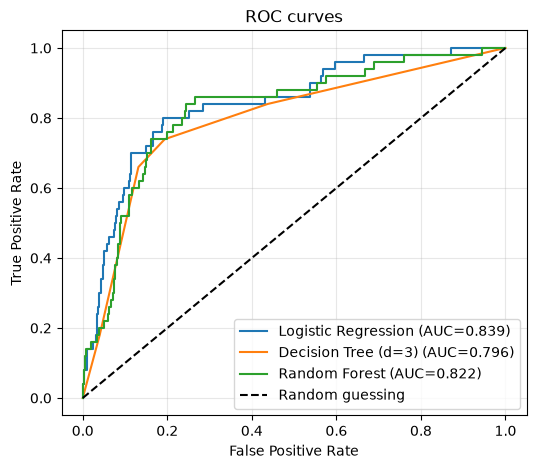

In [16]:
plt.figure(figsize=(6, 5))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC curves')
plt.legend(); plt.grid(alpha=.3); plt.show()

**3. Draw Precision-Recall curves for the same models on a second chart. Add a horizontal line at the no-skill level
(the stroke rate) and put the average precision in the legend.**

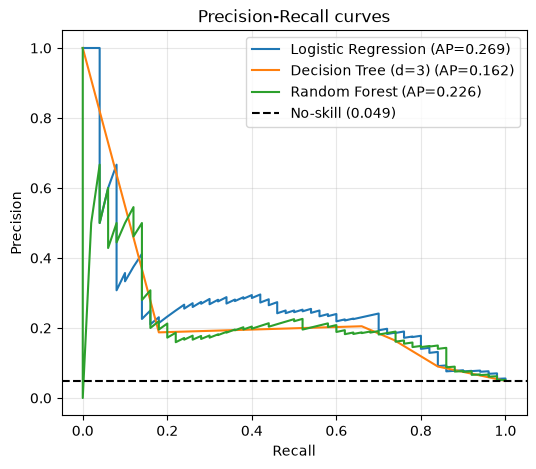

In [17]:
plt.figure(figsize=(6, 5))
for name, p in test_probs.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    plt.plot(rc, pr, label=f'{name} (AP={average_precision_score(y_test, p):.3f})')
plt.axhline(y_test.mean(), color='k', ls='--', label=f'No-skill ({y_test.mean():.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall curves')
plt.legend(); plt.grid(alpha=.3); plt.show()

**ROC Curve Interpretation:**

*All three models perform better than random guessing. Logistic Regression has the highest AUC (0.839), followed by Random Forest (0.822) and Decision Tree (0.796). Logistic Regression and Random Forest perform similarly. The Decision Tree curve is simpler because it produces fewer probability values.*

**Precision-Recall Curve Interpretation:**

*All three models perform better than random guessing, whose baseline is 0.049. Logistic Regression has the highest AP (0.269), followed by Random Forest (0.226) and Decision Tree (0.162). Precision decreases as recall increases, meaning detecting more stroke patients also results in more false alarms. The curves are uneven because the test set contains only 50 stroke patients.*

# Task 3.2 — Choose a decision threshold

**1. The hospital wants to catch at least 80% of strokes. Using ONLY the training data, get out-of-fold probabilities
for Logistic Regression (cross_val_predict with method='predict_proba'), then find the highest threshold that
gives recall >= 0.80 on them.**

In [18]:
oof = cross_val_predict(LogisticRegression(max_iter=1000), X_train_s, y_train,
                        cv=skf, method='predict_proba')[:, 1]

fpr, tpr, thr = roc_curve(y_train, oof)
idx = np.argmax(tpr >= 0.80)      
threshold = thr[idx]

print("Chosen threshold:", round(threshold, 4))
print("Out-of-fold recall at this threshold:", round(tpr[idx], 3))

Chosen threshold: 0.0509
Out-of-fold recall at this threshold: 0.804


**2. Apply that threshold to the test probabilities. Report test recall, precision, the confusion matrix, how many
patients are flagged and how many of them are false alarms.**

Test recall   : 0.82
Test precision: 0.135
Confusion matrix:
 [[709 263]
 [  9  41]]
Patients flagged: 304 | False alarms (FP): 263 | Missed strokes (FN): 9


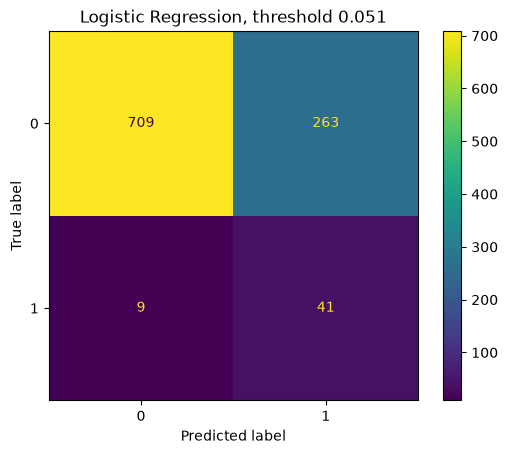

In [19]:
lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
p_test = lr.predict_proba(X_test_s)[:, 1]
pred = (p_test >= threshold).astype(int)

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()

print("Test recall   :", round(recall_score(y_test, pred), 3))
print("Test precision:", round(precision_score(y_test, pred), 3))
print("Confusion matrix:\n", cm)
print("Patients flagged:", pred.sum(), "| False alarms (FP):", fp, "| Missed strokes (FN):", fn)

ConfusionMatrixDisplay(cm).plot()
plt.title(f"Logistic Regression, threshold {threshold:.3f}")
plt.show()

**Threshold Interpretation:**

*The threshold of 0.0509 was selected using training data only. On the test set, recall increased to 0.82, detecting 41 out of 50 strokes. However, precision was only 0.135. The model flagged 304 patients, including 263 false alarms, and missed 9 strokes. Compared with the default threshold of 0.5, recall improved significantly from 0.02 to 0.82.*

**(a)** 
*ROC AUC (0.839) measures how well the model ranks stroke patients above non-stroke patients across different thresholds. However, the default threshold of 0.5 was too high, resulting in only 1 detected stroke. Lowering the threshold to 0.0509 increased recall to 0.82 without changing the model.*

**(b)** 
*The Precision-Recall curve is more useful for this imbalanced dataset because it directly shows the trade-off between detecting stroke patients and false alarms. ROC AUC can look good even when many false positives occur. The PR curve shows that achieving high recall requires accepting more false alarms.*

**(c)** 
*The model detected 41 strokes but produced 263 false alarms and missed 9 strokes. This may be acceptable if follow-up tests are inexpensive and missing a stroke is much more dangerous. However, too many false alarms can increase hospital workload, costs, and patient anxiety.*

# Part 4 — Undersampling, Oversampling and SMOTE 

# Task 4.1 — Compare the methods

**1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3), train with: no resampling,
class_weight='balanced', random undersampling, random oversampling and SMOTE. Resample the TRAIN set
only; the test set is never touched.**

In [20]:
def get_model(kind, cw=None):
    if kind == 'LogReg':
        return LogisticRegression(max_iter=1000, class_weight=cw)
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                  class_weight=cw, random_state=SEED, n_jobs=-1)

methods = {
    'No resampling': (None, None),
    'class_weight=balanced': ('balanced', None),
    'Undersampling': (None, RandomUnderSampler(random_state=SEED)),
    'Oversampling': (None, RandomOverSampler(random_state=SEED)),
    'SMOTE': (None, SMOTE(random_state=SEED))}

results = []
for kind in ['LogReg', 'RF']:
    # Logistic Regression uses the scaled data, Random Forest uses the original data
    Xtr, Xte = (X_train_s, X_test_s) if kind == 'LogReg' else (X_train, X_test)
    for mname, (cw, sampler) in methods.items():
        # resample the TRAIN set only; the test set is never touched
        if sampler is None:
            Xr, yr = Xtr, y_train
        else:
            Xr, yr = sampler.fit_resample(Xtr, y_train)
        r = evaluate(get_model(kind, cw), Xr, yr, Xte, y_test)
        results.append({'Model + method': f'{kind} + {mname}',
                        'Train rows': len(yr),
                        'Train strokes': int(np.sum(yr)),
                        'Precision': r['Precision'], 'Recall': r['Recall'],
                        'F1': r['F1'], 'ROC AUC': r['ROC AUC'], 'PR AUC': r['PR AUC']})
print("Done:", len(results), "models trained")

Done: 10 models trained


**2. Build ONE table (rows = model + method) with: number of training rows, number of strokes in training,
Precision, Recall, F1, ROC AUC and PR AUC on the test set.**

In [21]:
table41 = pd.DataFrame(results).round(3)
table41

,Model + method,Train rows,Train strokes,Precision,Recall,F1,ROC AUC,PR AUC
0,LogReg + No resampling,4087,199,1.000,0.02,0.039,0.839,0.269
1,LogReg + class_weight=balanced,4087,199,0.135,0.80,0.231,0.840,0.260
2,LogReg + Undersampling,398,199,0.125,0.82,0.216,0.835,0.234
3,LogReg + Oversampling,7776,3888,0.133,0.80,0.229,0.838,0.265
4,LogReg + SMOTE,7776,3888,0.134,0.80,0.229,0.841,0.288
5,RF + No resampling,4087,199,0.000,0.00,0.000,0.822,0.226
6,RF + class_weight=balanced,4087,199,0.189,0.72,0.300,0.815,0.199
7,RF + Undersampling,398,199,0.105,0.84,0.187,0.820,0.203
8,RF + Oversampling,7776,3888,0.188,0.32,0.237,0.811,0.191
9,RF + SMOTE,7776,3888,0.500,0.06,0.107,0.798,0.229


**Interpretation:**
*All resampling methods were applied only to the training data, while the test set remained unchanged. Undersampling reduced training rows to 398, while oversampling and SMOTE increased them to 7,776.*

**Question (a): Logistic Regression**
*Recall increased from 0.02 without resampling to around 0.80–0.82 with resampling. However, precision decreased from 1.00 to around 0.13. F1-score improved, while ROC AUC remained almost unchanged. This shows that resampling helped detect more stroke patients but did not significantly improve the model's ability to distinguish between classes.*

**Question (b): Random Forest vs Logistic Regression**
*Random Forest did not respond consistently to resampling. Class weighting and undersampling achieved recall of 0.72 and 0.84, while oversampling and SMOTE achieved only 0.32 and 0.06. Logistic Regression showed more consistent results, with recall around 0.80 across most resampling methods. This may be because Random Forest is more sensitive to duplicated and synthetic training samples.*

# Task 4.2 — The classic mistake

**1. Apply SMOTE to ALL the data first (train + test together), THEN split 80/20, train a Random Forest and
evaluate. This is the wrong order.**

In [22]:
X_all = X.fillna(X.median())
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_all, y)
Xa, Xb, ya, yb = train_test_split(X_sm, y_sm, test_size=0.2,
                                  stratify=y_sm, random_state=SEED)
r_wrong = evaluate(get_model('RF'), Xa, ya, Xb, yb)
print({k: round(v, 3) for k, v in r_wrong.items()})

{'Accuracy': 0.972, 'Precision': 0.996, 'Recall': 0.948, 'F1': 0.971, 'ROC AUC': 0.995, 'PR AUC': 0.996}


**2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.**

In [23]:
r_right = table41[table41['Model + method'] == 'RF + SMOTE'].iloc[0]
cols = ['Precision', 'Recall', 'F1', 'ROC AUC', 'PR AUC']
cmp = pd.DataFrame([
    {'Order': 'WRONG (SMOTE, then split)', **{k: r_wrong[k] for k in cols}},
    {'Order': 'CORRECT (split, then SMOTE)', **{k: r_right[k] for k in cols}}])
cmp.round(3)

,Order,Precision,Recall,F1,ROC AUC,PR AUC
0,"WRONG (SMOTE, then split)",0.996,0.948,0.971,0.995,0.996
1,"CORRECT (split, then SMOTE)",0.500,0.060,0.107,0.798,0.229


**Interpretation:**
*Applying SMOTE before splitting produced very high scores, including 0.948 recall and 0.995 ROC AUC. However, splitting after SMOTE causes data leakage because synthetic samples related to the same patients can appear in both training and testing sets. This makes the test results unrealistically good. The correct approach is to split the data first, apply SMOTE only to the training set, and evaluate on untouched test data.*

**Question (c): Why are the wrong-order results unreliable?**
*SMOTE created synthetic stroke patients using information from the entire dataset before splitting. Related synthetic patients could then appear in both training and test sets, allowing the model to learn information about test patients. The test set also no longer represents the original patient distribution. Therefore, the high scores cannot be trusted to represent performance on new patients. Always split first and resample only the training data.*

**Question (d): Which rebalancing method would you choose?**
*I would choose Logistic Regression with class_weight='balanced' because it is simple and achieves recall of 0.80 with PR AUC of 0.260. Its performance is similar to oversampling and SMOTE without creating extra data. Undersampling loses many healthy patients, while SMOTE adds complexity. The slightly higher SMOTE PR AUC (0.288) is not enough to confidently justify the extra complexity.*

# Part 5 — Noisy Data

# Task 5.1 — Label noise

**1. Write a function that flips a given fraction of the training labels at random (0 becomes 1 and 1 becomes 0).**

In [24]:
def make_models():
    return {'LogReg': (LogisticRegression(max_iter=1000), True),
            'Tree d=3': (DecisionTreeClassifier(max_depth=3, random_state=SEED), False),
            'Tree None': (DecisionTreeClassifier(random_state=SEED), False),
            'RandomForest': (RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                    random_state=SEED, n_jobs=-1), False)}

def test_auc_all(Xtr, ytr, Xte, yte):
    sc = StandardScaler().fit(Xtr)               
    out = {}
    for name, (m, scaled) in make_models().items():
        a, b = (sc.transform(Xtr), sc.transform(Xte)) if scaled else (Xtr, Xte)
        m.fit(a, ytr)
        out[name] = roc_auc_score(yte, m.predict_proba(b)[:, 1])
    return out
    
def flip_labels(y, frac, rng):
    y_new = np.array(y).copy()
    idx = rng.choice(len(y_new), int(frac * len(y_new)), replace=False)
    y_new[idx] = 1 - y_new[idx]          
    return y_new

rng = np.random.default_rng(SEED)
y_check = flip_labels(y_train, 0.10, rng)
print("Labels changed:", int((y_check != np.array(y_train)).sum()), "of", len(y_train))

Labels changed: 408 of 4087


**2. For fractions 0, 0.05, 0.10 and 0.20, train each model on the noisy labels and record the test ROC AUC.
Repeat 5 times with different random flips and average (use 1 repeat for fraction 0).**

In [25]:
rows = {}
for frac in [0, 0.05, 0.10, 0.20]:
    reps = 1 if frac == 0 else 5
    res = []
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        res.append(test_auc_all(X_train, flip_labels(y_train, frac, rng), X_test, y_test))
    rows[frac] = pd.DataFrame(res).mean()
print("Done")

Done


**3. Show a table (rows = noise fraction, columns = models) and a line plot.**

,LogReg,Tree d=3,Tree None,RandomForest
label noise,,,,
0.00,0.839,0.796,0.580,0.822
0.05,0.824,0.801,0.553,0.803
0.10,0.805,0.783,0.512,0.753
0.20,0.774,0.726,0.505,0.683


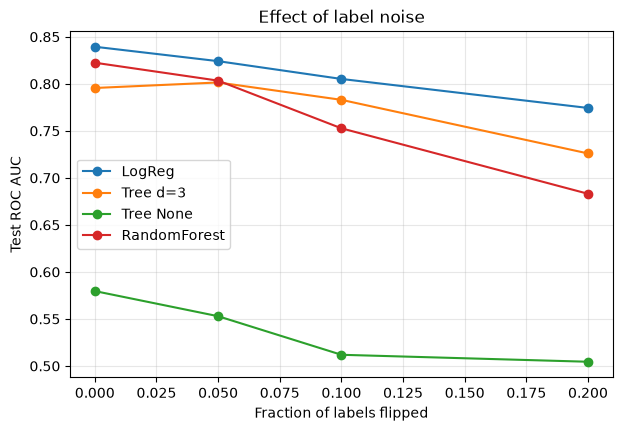

In [26]:
label_tbl = pd.DataFrame(rows).T
label_tbl.index.name = 'label noise'
display(label_tbl.round(3))

label_tbl.plot(marker='o', figsize=(7, 4.5))
plt.ylabel('Test ROC AUC'); plt.xlabel('Fraction of labels flipped')
plt.title('Effect of label noise'); plt.grid(alpha=.3); plt.show()

**Interpretation:**
*Test ROC AUC decreases as label noise increases. Logistic Regression performs best and is the most stable, dropping from 0.839 to 0.774. Random Forest shows the largest drop, from 0.822 to 0.683. The unrestricted Decision Tree reaches 0.505 at 20% noise, which is close to random guessing. The small improvement of the depth-3 tree at 5% noise is likely due to random variation. Overall, Logistic Regression handles noisy labels best, while Random Forest is affected the most.*

# Task 5.2 — Feature noise

**1. Add Gaussian noise to the TRAIN values of age, avg_glucose_level and bmi: noise = random normal * (column
std) * level. Use levels 0, 0.5, 1 and 2, five repeats each, test set untouched.**

In [27]:
noisy_cols = ['age', 'avg_glucose_level', 'bmi']

def add_feature_noise(Xdf, level, rng):
    Xn = Xdf.copy()
    for c in noisy_cols:
        Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * Xdf[c].std() * level
    return Xn

rng = np.random.default_rng(SEED)
Xn = add_feature_noise(X_train, 1, rng)
print(X_train[noisy_cols].std().round(2).to_dict())
print(Xn[noisy_cols].std().round(2).to_dict())
rows_f = {}
for level in [0, 0.5, 1, 2]:
    reps = 5
    res = []
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        Xn = add_feature_noise(X_train, level, rng)
        res.append(test_auc_all(Xn, y_train, X_test, y_test))
    rows_f[level] = pd.DataFrame(res).mean()
print("Done")

{'age': 22.64, 'avg_glucose_level': 44.68, 'bmi': 7.74}
{'age': 31.97, 'avg_glucose_level': 63.4, 'bmi': 10.85}
Done


**2. Show the same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training
data.)**

,LogReg,Tree d=3,Tree None,RandomForest
feature noise level,,,,
0.0,0.839,0.796,0.580,0.822
0.5,0.834,0.799,0.561,0.814
1.0,0.810,0.761,0.528,0.787
2.0,0.770,0.694,0.531,0.741


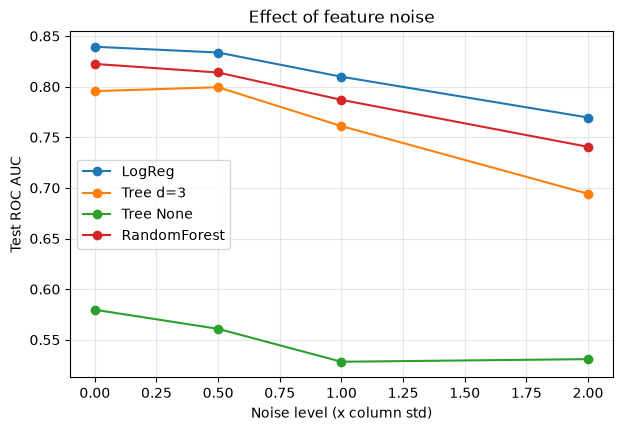

In [28]:
feat_tbl = pd.DataFrame(rows_f).T
feat_tbl.index.name = 'feature noise level'
display(feat_tbl.round(3))

feat_tbl.plot(marker='o', figsize=(7, 4.5))
plt.ylabel('Test ROC AUC'); plt.xlabel('Noise level (x column std)')
plt.title('Effect of feature noise'); plt.grid(alpha=.3); plt.show()

**Interpretation:**
*Adding noise to age, glucose level, and BMI reduces ROC AUC for all models. Logistic Regression performs best, dropping from 0.839 to 0.770. The depth-3 tree has the largest decrease, from 0.796 to 0.694. Random Forest drops from 0.822 to 0.741. The unrestricted tree performs poorly even without noise and ends near random guessing. Mild noise has little effect, but performance declines more after level 1. The small improvement in the depth-3 tree at level 0.5 is likely due to random variation.*

# Task 5.3 — SMOTE and noisy labels

**1. Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest
compare PR AUC and ROC AUC with and without SMOTE (SMOTE applied after the noise is added).**

In [29]:
rows53 = []
for kind in ['LogReg', 'RF']:
    Xtr, Xte = (X_train_s, X_test_s) if kind == 'LogReg' else (X_train, X_test)
    for use_smote in [False, True]:
        pr, roc = [], []
        for r in range(3):
            rng = np.random.default_rng(SEED + r)
            yn = flip_labels(y_train, 0.10, rng)          
            if use_smote:
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, yn)   
            else:
                Xr, yr = Xtr, yn
            res = evaluate(get_model(kind), Xr, yr, Xte, y_test)
            pr.append(res['PR AUC']); roc.append(res['ROC AUC'])
        rows53.append({'Model': kind, 'SMOTE': use_smote,
                       'PR AUC': np.mean(pr), 'ROC AUC': np.mean(roc)})
print("Done")

Done


In [30]:
table53 = pd.DataFrame(rows53).round(3)
table53

,Model,SMOTE,PR AUC,ROC AUC
0,LogReg,False,0.224,0.810
1,LogReg,True,0.231,0.810
2,RF,False,0.160,0.751
3,RF,True,0.111,0.667


**Interpretation:**
*With 10% label noise, SMOTE had little effect on Logistic Regression: PR AUC increased slightly from 0.224 to 0.231, while ROC AUC stayed at 0.810. For Random Forest, SMOTE reduced PR AUC from 0.160 to 0.111 and ROC AUC from 0.751 to 0.667. Since SMOTE was applied after adding noise, it generated synthetic samples using incorrect labels, which further harmed Random Forest.*

**Question (a): Most damaged and most stable model**
*Logistic Regression is the most stable model, maintaining the highest AUC across both noise experiments. Random Forest is most affected by label noise, with a drop of 0.139, while the depth-3 tree is most affected by feature noise, with a drop of 0.102. The unrestricted tree has smaller drops because its performance was already close to random guessing. This matches Part 2, where complex trees showed high variance and overfitting.*

**Question (b): Label noise vs feature noise**
*Label noise causes a slightly larger average AUC drop than feature noise (0.087 vs 0.075). However, the effect depends on the model: Random Forest is more affected by label noise, while the depth-3 tree is more affected by feature noise. Label noise changes the correct target values, while feature noise makes the input data less reliable but keeps labels correct.*

**Question (c): SMOTE with noisy labels**
*SMOTE had almost no effect on Logistic Regression but reduced Random Forest performance. SMOTE creates new minority-class samples using existing minority labels. When labels are incorrect, it can generate synthetic samples based on wrong information. Random Forest may learn these misleading patterns, reducing its ability to identify real stroke patients.*

# Part 6 — Final Decision and Conclusion

**1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on
the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false
alarms and number of missed strokes.**

In [31]:
oof = cross_val_predict(LogisticRegression(max_iter=1000), X_train_s, y_train,
                        cv=skf, method='predict_proba')[:, 1]
fpr, tpr, thr = roc_curve(y_train, oof)
threshold = thr[np.argmax(tpr >= 0.80)]

lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
p = lr.predict_proba(X_test_s)[:, 1]

def summarize(pred, label):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'Setting': label,
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred, zero_division=0),
            'False alarms (FP)': fp, 'Missed strokes (FN)': fn}

final = pd.DataFrame([summarize((p >= 0.5).astype(int), 'Default threshold 0.5'),
                      summarize((p >= threshold).astype(int), f'Chosen threshold {threshold:.3f}')])
final.round(3)

,Setting,Precision,Recall,F1,False alarms (FP),Missed strokes (FN)
0,Default threshold 0.5,1.000,0.02,0.039,0,49
1,Chosen threshold 0.051,0.135,0.82,0.232,263,9


**Interpretation:**
*At the default threshold of 0.5, the model detects only 1 of 50 stroke patients, giving recall of 0.02. At the tuned threshold of 0.051, it detects 41 patients, increasing recall to 0.82 and F1 to 0.232. However, it produces 263 false alarms and still misses 9 strokes. Therefore, the lower threshold detects more strokes but increases false alarms.*

**2. Write an Executive Summary (6-8 lines): what you chose, its recall and precision with numbers, the price
paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and
about the choice of threshold).**

*I selected Logistic Regression with a threshold of 0.051, chosen using training data to achieve at least 80% recall. On the test set, it detects 41 of 50 stroke patients (recall 0.82), compared with only 1 patient at the default threshold of 0.5. It flags 304 patients, including 263 false alarms, and misses 9 strokes. This approach is suitable only if the hospital can manage the additional follow-up checks. Data preprocessing and threshold selection were performed using training data only to avoid leakage. A limitation is that the test set contains only 50 stroke patients, so results may vary on new data. I chose threshold tuning over resampling because resampling methods achieved similar recall and did not improve ROC AUC.*

**Final Reflection**

**(a) Most surprising result**

*The most surprising result was that Logistic Regression had a high ROC AUC (0.839) but caught only 1 of 50 stroke patients at the default threshold of 0.5 (recall 0.02). Its accuracy was 0.9521, slightly higher than the baseline accuracy of 0.9511. Lowering the threshold to 0.051 increased recall to 0.82 (41 of 50 strokes). This showed me that accuracy can be misleading on imbalanced data and that threshold selection is important.*

**(b) If I had one more hour**

*I would use repeated stratified cross-validation to check how stable recall is, because the test set contains only 50 stroke patients. I would also select a threshold based on the hospital’s cost of missed strokes versus false alarms to reduce unnecessary alerts. Finally, I would try XGBoost with class weights and compare its PR AUC with Logistic Regression.*